# CSAI3121 - Machine Learning and Intelligent Data Analysis
## Lab 5 - Linear SVM, GridSearchCV, and Cross-Validation

**Goal for today:** train a Linear SVM, investigate the effect of `C`, and tune `C` using 5-fold cross-validation.

By the end of this lab, you should be able to:
1. Fit and visualize a Linear SVM.
2. Explain the role of `C`.
3. Use `GridSearchCV` without using the test set for model selection.
4. Compare cross-validation accuracy with final test accuracy.

The plotting helper is provided so you can focus your coding on model training and evaluation.


In [78]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.pyplot import cm

from sklearn import svm
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import GridSearchCV, train_test_split

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.3f}")


In [79]:
# Provided helper: dashed lines are margins, the solid line is the boundary,
# and circles mark support vectors.

def plot_decision_boundary(X, y, clf, title, plot_sv=True):
    fig, ax = plt.subplots(figsize=(4, 4))

    DecisionBoundaryDisplay.from_estimator(
        clf, X, ax=ax, response_method="predict",
        plot_method="pcolormesh", alpha=0.25
    )
    DecisionBoundaryDisplay.from_estimator(
        clf, X, ax=ax, response_method="decision_function",
        plot_method="contour", levels=[-1, 0, 1],
        colors=["black"] * 3, linestyles=["--", "-", "--"]
    )

    if plot_sv:
        ax.scatter(
            clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=150, facecolors="none", edgecolors="black",
            linewidths=1.2, label="support vectors"
        )

    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=cm.coolwarm, edgecolors="none")
    ax.set_xlabel("Feature 1")
    ax.set_ylabel("Feature 2")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


## Dataset

Run this cell to create and view a small two-class dataset.


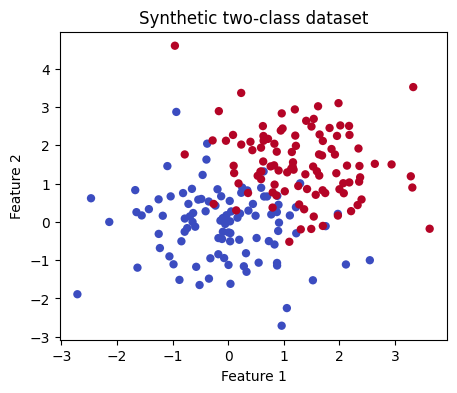

In [80]:
rng = np.random.default_rng(1)
X = rng.standard_normal((200, 2))
y = np.array([-1] * 100 + [1] * 100)
X[y == 1] += 1.5

plt.figure(figsize=(5, 4))
plt.scatter(X[:, 0], X[:, 1], c=y, cmap=cm.coolwarm, edgecolors="none")
plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Synthetic two-class dataset")
plt.show()


## Task 1. Fit a Linear SVM and Investigate `C`

First fit a Linear SVM with `C=1`. Print the training accuracy and number of support vectors, then visualize the boundary.

Next, compare `C=0.01` and `C=100`. Use a loop if helpful. For each value, print the same information and plot the result.

Recall:
- Smaller `C` allows more margin violations and usually gives a wider margin.
- Larger `C` penalizes violations more strongly and usually gives a narrower margin.

Useful tools: `svm.SVC(kernel="linear", C=...)`, `.fit()`, `.predict()`, `.n_support_`, `accuracy_score()`.

**Example structure:**
```python
model = svm.SVC(kernel="linear", C=YOUR_C_VALUE)
model.fit(X, y)
predictions = model.predict(X)
print(accuracy_score(y, predictions))
print(model.n_support_.sum())
plot_decision_boundary(X, y, model, title="...")
```

For the comparison, the pattern can be repeated in a loop:
```python
for C_value in [0.01, 100]:
    # create, fit, evaluate, and plot a new model here
    pass
```


0.9
53


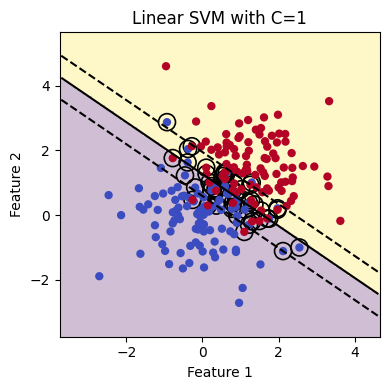

accuracy: 0.895
support vectors: 131


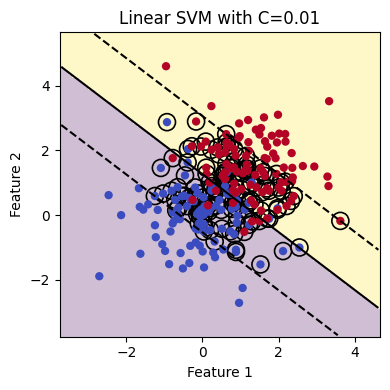

accuracy: 0.91
support vectors: 49


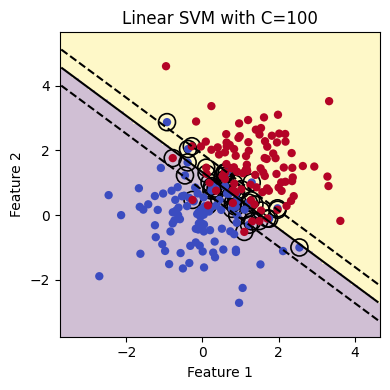

In [81]:
# TODO: fit and evaluate a Linear SVM with C=1.
model = svm.SVC(kernel='linear', C=1)
model.fit(X, y)
predictions = model.predict(X)
print(accuracy_score(y, predictions))
print(model.n_support_.sum())
plot_decision_boundary(X, y, model, "Linear SVM with C=1")

# TODO: compare C=0.01 and C=100.
# For each value, create a fresh model, fit it, print accuracy and
# support-vector count, and call plot_decision_boundary(...).
for C_value in [0.01, 100]:
      model = svm.SVC(kernel='linear', C=C_value)
      model.fit(X, y)
      predictions = model.predict(X)
      print("accuracy:", accuracy_score(y, predictions))
      print("support vectors:", model.n_support_.sum())
      plot_decision_boundary(X, y, model, f"Linear SVM with C={C_value}")

## Task 2. Split the Data and Tune `C`

Create a training set and a test set using `test_size=0.30`, `random_state=10`, and `stratify=y`.

Then use `GridSearchCV` to compare the candidate values:
`[0.001, 0.01, 0.1, 1, 10, 100]`

Use a Linear SVM, 5-fold cross-validation, and accuracy scoring. Fit the grid search on the training set only.

Do not use the test set while choosing `C`.

**Example structure:**
```python
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=10, stratify=y
)

grid = GridSearchCV(
    estimator=svm.SVC(kernel="linear"),
    param_grid=param_grid,
    cv=5,
    scoring="accuracy"
)
grid.fit(X_train, y_train)
```


In [82]:
# TODO: create X_train, X_test, y_train, and y_test.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=10, stratify=y)

param_grid = {"C": [0.001, 0.01, 0.1, 1, 10, 100]}

# TODO: create a GridSearchCV object called `grid`.
# Use svm.SVC(kernel="linear"), cv=5, and scoring="accuracy".
grid = GridSearchCV(estimator=svm.SVC(kernel='linear'),
                    param_grid=param_grid,
                    cv=5,
                    scoring='accuracy')


# TODO: fit grid using X_train and y_train.
grid.fit(X_train, y_train)

GridSearchCV(cv=5, estimator=SVC(kernel='linear'),
             param_grid={'C': [0.001, 0.01, 0.1, 1, 10, 100]},
             scoring='accuracy')

In [83]:
print(param_grid)

{'C': [0.001, 0.01, 0.1, 1, 10, 100]}


## Task 3. Inspect Results and Evaluate the Final Model

Inspect which values of `C` were tried and their mean cross-validation scores. Then save the best estimator.

Finally, evaluate the selected model once on the untouched test set:
- print the best `C`;
- print mean CV accuracy and test accuracy;
- display a confusion matrix;
- plot the test-set decision boundary.

Remember: `grid.best_score_` is the mean validation accuracy across the folds, not the final test accuracy.

**Example structure:**
```python
cv_results = pd.DataFrame(grid.cv_results_)
cv_summary = cv_results[["param_C", "mean_test_score", "rank_test_score"]]

best_model = grid.best_estimator_
y_test_pred = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
```

For the confusion matrix, use a pattern like this:
```python
conf_mat = confusion_matrix(y_test, y_test_pred, labels=[-1, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat, display_labels=["-1", "+1"])
disp.plot(cmap=plt.cm.Blues)
plt.show()

plot_decision_boundary(X_test, y_test, best_model,
                       title="Best Linear SVM", plot_sv=False)
```


  param_C  mean_test_score  std_test_score  rank_test_score
0   0.001            0.921           0.052                2
1   0.010            0.921           0.057                2
2   0.100            0.921           0.047                2
3       1            0.929           0.045                1
4      10            0.914           0.058                5
5     100            0.907           0.058                6
Best parameters: {'C': 1}
Best score: 0.9285714285714286
Test accuracy: 0.8666666666666667


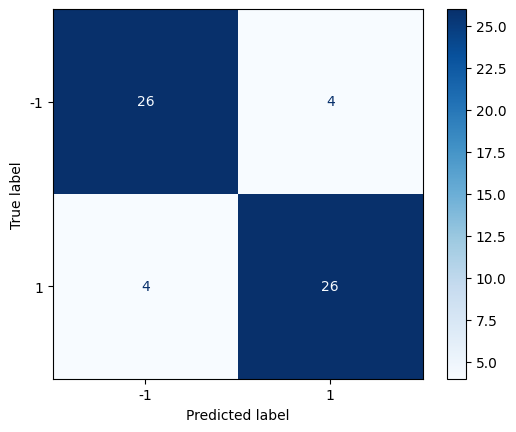

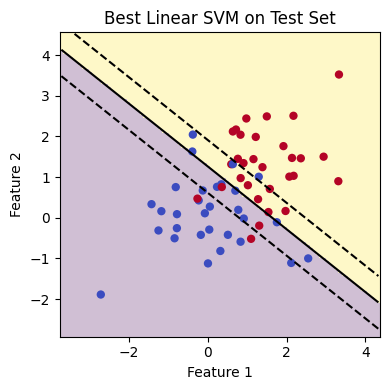

In [84]:
# TODO: convert grid.cv_results_ into a DataFrame and display 
# cv_summary which includes
# param_C, mean_test_score, std_test_score, and rank_test_score
cv_results = pd.DataFrame(grid.cv_results_)
cv_summary = cv_results[["param_C", "mean_test_score", "std_test_score", "rank_test_score"]]
print(cv_summary)


# TODO: print grid.best_params_ and grid.best_score_.
# TODO: save grid.best_estimator_ as best_model.
print("Best parameters:", grid.best_params_)
print("Best score:", grid.best_score_)
best_model = grid.best_estimator_

# TODO: predict y_test, calculate test accuracy, and compare it with
# grid.best_score_.
y_test_pred = best_model.predict(X_test)
test_accuracy = accuracy_score(y_test, y_test_pred)
print("Test accuracy:", test_accuracy)

# TODO: display a confusion matrix and plot the selected model
# on the test set.
conf_mat = confusion_matrix(y_test, y_test_pred, labels=[-1, 1])
disp = ConfusionMatrixDisplay(confusion_matrix=conf_mat, display_labels=["-1", "1"])
disp.plot(cmap=plt.cm.Blues)
plt.show()


plot_decision_boundary(X_test, y_test, best_model, title="Best Linear SVM on Test Set", plot_sv=False)

## Final Checkpoint

Answer these before leaving:
1. What does `C` control?
2. Why must the test set stay out of `GridSearchCV`?
3. Why might mean CV accuracy and test accuracy differ?
